In [1]:
import scanpy as sc
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

from dataprocess.h5a import H5ADTokenizer
from dataprocess.genepep import GenePepExtractor
from model.const import set_species_context
from model import data
import model.resa as resa
import model.utils as utils
import model.mmd as mmd
import model.lr_schedule as lr_sche

In [2]:
organ='hippocampus'
species_to_adata = {
    "homo_sapiens": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/h5data/{organ}/homo_sapiens.h5ad"),
    "Sus_scrofa": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/h5data/{organ}/Sus_scrofa.h5ad"),
    "Macaca_mulatta": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/h5data/{organ}/Macaca_mulatta.h5ad"),
}


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/anndata/_core/anndata.py:1756: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/anndata/_core/anndata.py:1756: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/anndata/_core/anndata.py:1756: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [3]:
species_to_embed_file = {
    "homo_sapiens": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/homo_sapiens.avg.embeddings",
    "Sus_scrofa": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/Sus_scrofa.avg.embeddings",
    "Macaca_mulatta": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/Macaca_mulatta.avg.embeddings",
}


In [4]:
set_species_context(species_to_adata)

{'homo_sapiens': 0, 'Sus_scrofa': 1, 'Macaca_mulatta': 2}

In [5]:
tokenized = H5ADTokenizer(
    species_to_adata,
    species_to_embed_file,
).process_species_adata()

100%|██████████| 36107/36107 [00:00<00:00, 41091.58it/s]


In [6]:
tokenized

{'homo_sapiens': AnnData object with n_obs × n_vars = 219058 × 27875
     obs: 'cell_name', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'samplename', 'region', 'cluster', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'coarse_cluster'
     var: 'gene_name', 'ensembl_id', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'embed_statue'
     uns: 'gene_embeddings', 'gene_token', 'input_ids_flat', 'input_ids_indptr', 'log1p', 'pca'
     obsm: 'X_pca'
     varm: 'PCs'
     layers: 'counts',
 'Sus_scrofa': AnnData object with n_obs × n_vars = 36851 × 24928
     obs: 'cell', 'cell_name', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.ribo', 'samplename', 'PMI', 'cluster', 'species', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total

In [7]:
species_to_reps = {
    "homo_sapiens": "X_pca",
    "Sus_scrofa": "X_pca",
    "Macaca_mulatta": "X_pca",
}


In [8]:
train_loader, test_loader = data.prepare_multispecies_dataloaders(
    tokenized,
    batch_size=512,
    species_to_reps=species_to_reps,
    batch_species=3,
)

homo_sapiens: X_pca
Sus_scrofa: X_pca
Macaca_mulatta: X_pca


In [9]:
embed_size=480
d_model=120
scale=4
input_size=50
latent_size=64
num_layers=1
n_clusters=100000
net=resa.ReSA(species_to_embed_file,d_model,embed_size,latent_size,num_layers,n_clusters,scale=scale,)

PCA ing
PCA done


In [10]:
def train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,current_temp,scheduler,ml_weight=1.0):
    net.train()
    metrics=utils.Accumulator(4)
    pbar=tqdm(train_loader,desc='Processing')
    for _,batch in enumerate(pbar):
        optimizer.zero_grad(set_to_none=True)

        data,adata,sp=batch
        data = data.to(device, non_blocking=True)
        adata = adata.float().to(device, non_blocking=True)
        sp = sp.to(device, non_blocking=True)

        with autocast('cuda'):
            sl = torch.tensor(0.0, device=device)
            protein_features,gene_features,logit_scale=net(adata,data,sp,)
            species_ids = torch.unique(sp).tolist()
            #for i in torch.unique(sp):
            for s in species_ids:
                mask = (sp == s)

                indices = torch.nonzero(mask).squeeze(1)
                protein_features_i = torch.index_select(protein_features, 0, indices)
                gene_features_i = torch.index_select(gene_features, 0, indices)
                sl += loss_fn(protein_features_i, gene_features_i, logit_scale,temp=current_temp)
            ml=loss_fn1(protein_features,sp)
            loss=sl+ml*ml_weight

        scaler.scale(loss).backward()
        if net.transformer.embed.gene_embed.weight.grad is not None:
            #net.transformer.embed.gene_embed.weight.grad[3:-1] = 0
            net.transformer.embed.gene_embed.weight.grad[4:] = 0
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        if scheduler:
            scheduler.step()
        lr=optimizer.param_groups[0]['lr']
        pbar.set_description(f"loss:{loss.detach().item():.4f},sl:{sl.detach().item():.8f},ml:{ml.detach().item():.8f},lr:{lr:.8f}")
        metrics.add(loss.detach().item() * len(sp), sl.detach().item() * len(sp),ml.detach().item() * len(sp), len(sp))

    return {'loss':metrics[0] / metrics[3],'sl':metrics[1] / metrics[3],'ml':metrics[2] / metrics[3],}

def train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp,ml_weight):
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv1d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('init done')

    device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('training on', device)
    net.to(device)

    loss_fn=resa.ReSALoss()#swav.ATACKNNLoss()#
    loss_fn1=mmd.MMMD(kernel_type='rbf',each=True)#mmd.MSampleLoss(each=True)#
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr,fused=True)
    scheduler = lr_sche.CosineAnnealingWarmupRestarts(
        optimizer,
        first_cycle_steps=2000,   # 一个周期 2000 batch
        cycle_mult=1,             # 不增加周期长度
        max_lr=lr*1.5,            # 最大 lr 稍高
        min_lr=1e-6,
        warmup_steps=400,         # 前 400 batch 线性升到 max_lr
        gamma=0.6
    )
    early_stopping = utils.EarlyStopping(
        patience=10,               # 连续5个epoch指标不提升就停止
        verbose=True, 
        path=net_path, # 保存的文件名
        mode='min'                # 如果监控的是准确率，这里改用 'max'
    )
    scaler = GradScaler('cuda')
    cr_ml_weight=0.0
    warm_epoch=5
    try:
        for epoch in range(epochs):
            print(f"epoch:{epoch},")
            print(f"Temp: {temp}")
            if epoch>=warm_epoch:
                cr_ml_weight=ml_weight
            losses=train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,temp,scheduler,cr_ml_weight)
            current_lr = optimizer.param_groups[0]['lr']
            print(f"lr:{current_lr},")
            print(f'{losses}')
            if epoch>=warm_epoch:
                early_stopping(losses['loss'],net)
                if early_stopping.early_stop:
                    print("====== Early stopping triggered! ======")
                    #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                    break
            if epoch ==epochs-1:
                torch.save(net.state_dict(), net_path)
                print(f'saving weight in {net_path}')
                #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                break
    except KeyboardInterrupt:
        #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
        torch.save(net.state_dict(), net_path)
        print(f'saving weight in {net_path}')
        

In [11]:
# 新数据集复现实验不预加载已有权重；直接使用上面初始化的 net 训练。
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
#net.load_state_dict(torch.load(net_path,weights_only=True))

In [12]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
species_to_h5=tokenized
epochs=10
lr=1e-3
train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.2,ml_weight=0.0)


init done
training on cuda
epoch:0,
Temp: 0.2


loss:11.5403,sl:11.54031754,ml:0.62572420,lr:0.00122027: 100%|██████████| 855/855 [01:16<00:00, 11.17it/s]


lr:0.0012202669793037924,
{'loss': 12.195243337977002, 'sl': 12.195243337977002, 'ml': 0.6966907781467103}
epoch:1,
Temp: 0.2


loss:11.7004,sl:11.70035934,ml:0.71501368,lr:0.00011926: 100%|██████████| 855/855 [01:17<00:00, 11.08it/s]


lr:0.00011925818332964333,
{'loss': 11.61196927633899, 'sl': 11.61196927633899, 'ml': 0.6485307927717242}
epoch:2,
Temp: 0.2


...

lr:0.0002673858598053246,
{'loss': 11.530874073853967, 'sl': 11.530874073853967, 'ml': 0.58087992866834}
EarlyStopping counter: 1 out of 10
epoch:8,
Temp: 0.2


loss:11.5046,sl:11.50464439,ml:0.57046092,lr:0.00002910: 100%|██████████| 855/855 [01:17<00:00, 11.06it/s]


lr:2.9104983797232973e-05,
{'loss': 11.526317168118661, 'sl': 11.526317168118661, 'ml': 0.5704471034264704}
Validation metric improved (11.530781 --> 11.526317). Saving model...
epoch:9,
Temp: 0.2


loss:11.6241,sl:11.62406158,ml:0.61275500,lr:0.00019024: 100%|██████████| 855/855 [01:17<00:00, 11.10it/s]


lr:0.0001902361304653046,
{'loss': 11.526144627799765, 'sl': 11.526144627799765, 'ml': 0.5677270683628773}
Validation metric improved (11.526317 --> 11.526145). Saving model...
saving weight in /mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_hippocampus.pth


infering:   0%|          | 0/571 [00:00<?, ?it/s]

infering: 100%|██████████| 571/571 [00:16<00:00, 35.59it/s]


computing PCA
    with n_comps=25


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


    finished (0:00:00)
Running MOT_Correction by 'inferred_species' -> adata.obsm['X_mot']
X_mot shape: (292016, 25)
computing neighbors


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/crs_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:18)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:03:56)


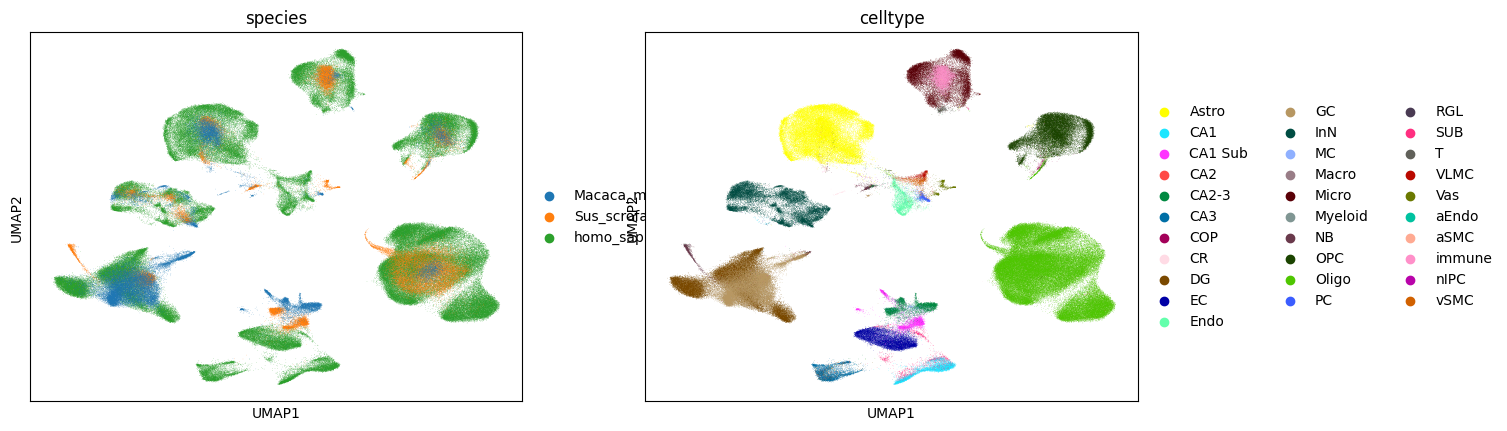

In [13]:
import importlib
import model.evaluate
importlib.reload(model.evaluate)
from model.evaluate import evaluate_integration

integrated_adata = evaluate_integration(
    net,
    test_loader,
    species_to_adata=tokenized,
    #metadata_columns=["cluster"],
    # 如果不同物种列名不一样，改用：
     species_to_metadata_columns={
         "one":["celltype"],
         "homo_sapiens": ["coarse_cluster",],
         "Sus_scrofa": ["cluster", ],
         "Macaca_mulatta": ["cluster", ],
     },
    embedding="protein",
    use_mot_correction=True,
    correction_by="inferred_species",
    correction_kwargs={
        "max_rounds": 10,
        "n_clusters": 10,
        "assignment_mode": "sinkhorn",
    },
    umap_colors=["species", "celltype"],
)


In [14]:
integrated_adata

AnnData object with n_obs × n_vars = 292016 × 64
    obs: 'species', 'celltype', 'inferred_species_token', 'inferred_species'
    uns: 'pca', 'neighbors', 'umap', 'species_colors', 'celltype_colors'
    obsm: 'X_pca', 'X_mot', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [15]:
from model.evaluate import _normalize_metadata_columns,_build_obs

_build_obs(species_to_adata,species_to_metadata_columns={
         "one":["celltype"],
         "homo_sapiens": ["coarse_cluster",],
         "Sus_scrofa": ["cluster", ],
         "Macaca_mulatta": ["cluster", ],
     },)

,species,celltype
0,homo_sapiens,CA3
1,homo_sapiens,CA3
2,homo_sapiens,CA3
3,homo_sapiens,CA3
4,homo_sapiens,CA3
...,...,...
36102,Macaca_mulatta,GC
36103,Macaca_mulatta,Astro
36104,Macaca_mulatta,InN
36105,Macaca_mulatta,GC
